In [1]:
# Project settings and paths: config.py is in the project root (this also makes the modules in src/ importable)
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())))
import config

import numpy as np
import ants
import h5py
from bart import bart
from glob import glob
from rrdftools.dataio import RRDF, dslice
from pathlib import Path
import pandas as pd
from datetime import datetime
from tqdm import tqdm
from scipy.ndimage import zoom

# Plotting related libraries
import plotly.express as px
import matplotlib.pyplot as plt

# Custom libraries
import dicom_load as dcmload
import calib_utils as cal

plt.style.use('dark_background')

# Define constants for throughout script
GAMMA = 42.577478518e6 # Hz/T

In [2]:
# Define directories and create directory for saving outputs to
parent_dir = config.B0_MAPPING_DIR
input_dir = parent_dir / "data"
deriv_dir = parent_dir / "derivatives"
Path.mkdir(deriv_dir, exist_ok=True)

In [3]:
# Scrape relevant raw data files
rrdf_fnames = glob(str(input_dir / "**/*.h5"))
rrdf_fnames.sort()
print(f"Identified {len(rrdf_fnames)} RRDF files in Input Directory")

# Next we need to extract the K-space data in order to be able to estimate phase maps
# additionally, we need the difference in TE between the sequences to convert phase to B0-inhomo.

rrdf_df = pd.DataFrame()
for fname in tqdm(rrdf_fnames):

    # Load RRDF and RRDF header
    rrdf = RRDF(fname)
    file_h5 = h5py.File(fname, 'r')
    rrdf_info = rrdf.info_dict()
    rrdf_series = pd.Series(rrdf_info)

    # Extract Sequence name for sorting
    seqname = file_h5["sequence"]["full_sequence_info"]["app_info"].attrs["sequence_name"].decode() 
    if seqname.endswith(".user"):
        seqname = seqname.replace(".user", "")
    rrdf_series["seq_name"] = seqname

    # Extract & convert to a datetime object for ease of sorting by scantime
    scantime = file_h5["process_info"].attrs["acquisition_datetime"].decode()
    dt_format = "%Y%m%d_%H%M%S"
    rrdf_series["scantime"] = datetime.strptime(scantime, dt_format)

    # Extract quantitative metrics about sequence
    rrdf_series["te"] = float(file_h5["sequence"].attrs[f"te"])
    rrdf_series["delta_te"] = float(file_h5["sequence"]["full_sequence_info"]["app_data"].attrs[f"delta_TE"])
    rrdf_series["f0"] = float(file_h5["calibration"].attrs["f0"]) # Hz
    rrdf_series["spacing"] = [float(file_h5["sequence"]["resolution"].attrs[f"i{i}"]) for i in range(3)]

    data, traj = rrdf.toBart()
    rrdf_series["kspace_data"] = data
    rrdf_series["kspace_traj"] = traj
    # print(f"data shape: {data.shape}, traj shape: {traj.shape}")
    
    # Store outputs from unpacking & reconstruction
    rrdf_df = pd.concat([rrdf_df, rrdf_series.to_frame().T], ignore_index=True)

Identified 20 RRDF files in Input Directory


 25%|██▌       | 5/20 [00:00<00:00, 46.49it/s]

('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>


 50%|█████     | 10/20 [00:00<00:00, 48.16it/s]

('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>


 75%|███████▌  | 15/20 [00:00<00:00, 47.52it/s]

('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<class 'numpy.ndarray'>
('CHAN', 'READOUT', 'ENC', 'ECHO')
[0 1 2 3]
('COORD', 'ENC', 'ECHO')
[0 1 2]
<cla

100%|██████████| 20/20 [00:00<00:00, 49.24it/s]


In [4]:
def apply_enlive_recon(data, traj, img_dim, echo_axis):

    # Slice object for separating data from odd & even echoes
    s_e0 = dslice(idx=echo_axis, slices=np.s_[0], ndim=len(data.shape))
    s_e1 = dslice(idx=echo_axis, slices=np.s_[1], ndim=len(data.shape))

    # ENLIVE reconstruction - regularisation not added as shown to be unnecessary for data collected.
    enlive_img0, enlive_sense0 = bart(2, f'nlinv -m1 -d3 -a240 -b40 -U -i8 -x {img_dim} -t', traj[s_e0], data[s_e0])
    enlive_img1, enlive_sense1 = bart(2, f'nlinv -m1 -d3 -a240 -b40 -U -i8 -x {img_dim} -t', traj[s_e1], data[s_e1])

    # Return complex images only, sense maps not necessary
    return enlive_img0, enlive_img1

img_dim = ':'.join([str(x) for x in rrdf_info['matrix']])
# Reconstruct the K-space data in each row of dataframe
rrdf_df[["img1", "img2"]] = rrdf_df.apply(lambda row: pd.Series(apply_enlive_recon(data=row["kspace_data"],
                                                                                   traj=row["kspace_traj"],
                                                                                   img_dim=img_dim,
                                                                                   echo_axis=5)), axis=1)

ksp : [  1  36 900   8   1   1   1   1   1   1   1   1   1   1   1   1 ]
cim : [ 36  36  36   8   1   1   1   1   1   1   1   1   1   1   1   1 ]
traj: [  3  36 900   1   1   1   1   1   1   1   1   1   1   1   1   1 ]
wgh : [  1  36 900   1   1   1   1   1   1   1   1   1   1   1   1   1 ]
NUFFT: Toeplitz mode

Model created (non Cartesian, nufft-based):
kspace:     [  1  36 900   8   1   1   1   1   1   1   1   1   1   1   1   1 ]
images:     [ 36  36  36   1   1   1   1   1   1   1   1   1   1   1   1   1 ]
coils:      [ 36  36  36   8   1   1   1   1   1   1   1   1   1   1   1   1 ]
trajectory: [  3  36 900   1   1   1   1   1   1   1   1   1   1   1   1   1 ]
pattern:    [  1  36 900   1   1   1   1   1   1   1   1   1   1   1   1   1 ]
coilimg:    [ 36  36  36   8   1   1   1   1   1   1   1   1   1   1   1   1 ]

NUFFT: Toeplitz mode
ksp : [  1  36 900   1   1   1   1   1   1   1   1   1   1   1   1   1   1 ]
cim : [ 72  72  72   1   1   1   1   1   1   1   1   1   1   1   1   

/var/folders/2x/cjhf7z5x01z_zb36hj149kqm0000gp/T/ipykernel_47309/4257979509.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig1.show()


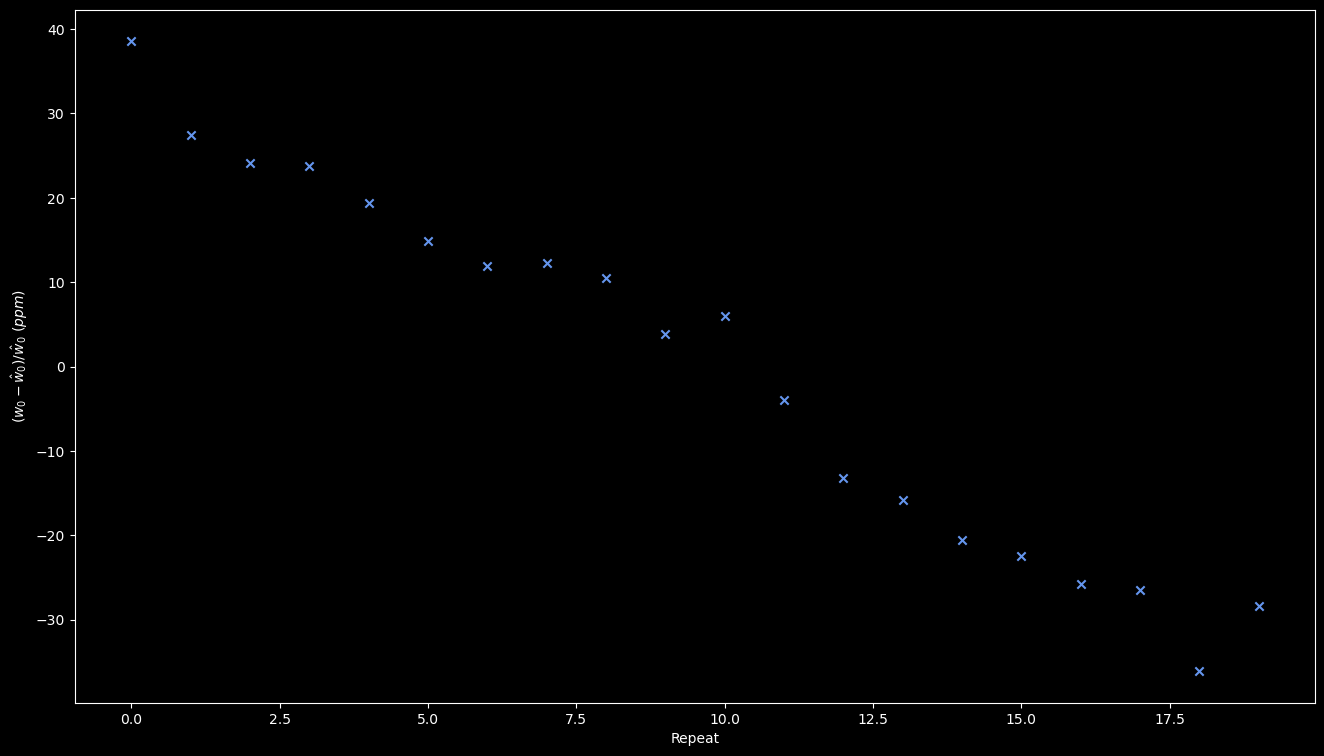

In [5]:
# The inhomogeneity scales with B0 flucatuations caused by temperature change.
# Inspection showed centre freq. varies notably across repeats
# Hence we shall output a normalised inhomo-map and combine these maps before
# finally referencing to a single B0.
fig1 = plt.figure(figsize=(16,9))
plt.scatter(x = rrdf_df.index.values, 
            y = 1e6 * (rrdf_df["f0"].values - rrdf_df["f0"].mean())/ rrdf_df["f0"].mean(), 
            c="cornflowerblue", 
            marker="x")
plt.ylabel(r"$(w_0 - \hat{w}_0) / \hat{w}_0 \ (ppm)$")
plt.xlabel("Repeat")
fig1.show()

In [6]:
def norm_inhomo_map(scan1, scan2, scan_f0, delta_te):
    
    # Calculate the phase difference between scans
    theta = np.angle(scan2 / scan1)
    w0_map = theta / delta_te # rad/s
    f0_map = w0_map / (2 * np.pi) # hz
    norm_map = f0_map / scan_f0 # unitless
    
    return norm_map

# Calculate normalise inhomogeneity maps
rrdf_df["inhomo_map"] = rrdf_df.apply(lambda row: norm_inhomo_map(scan1=row["img1"], 
                                                                  scan2=row["img2"], 
                                                                  scan_f0=row["f0"], 
                                                                  delta_te=row["delta_te"]), axis=1)

# Combine average maps and reference to mean B0 value
f0_avg = rrdf_df["f0"].mean()
inhomo_map_avg = rrdf_df["inhomo_map"].mean()
delta_w0_map = f0_avg * inhomo_map_avg
delta_B0_map = delta_w0_map / GAMMA #T

px.imshow(delta_B0_map, animation_frame=2, height=800, width=1000, title="B0-inhomogeneity")

In [7]:
# Also use the noise across the inhomogeneity maps to provide an initial signal mask
std_map = np.std(np.abs(np.stack(rrdf_df["inhomo_map"].values, axis=0)), axis=0)
epsilon = 1e-3
clean_signal = 1 / (std_map + epsilon)
mask = ants.get_mask(ants.from_numpy(clean_signal, spacing=[1,1,1]), low_thresh=np.percentile(clean_signal, 10), cleanup=2).numpy().astype(bool)

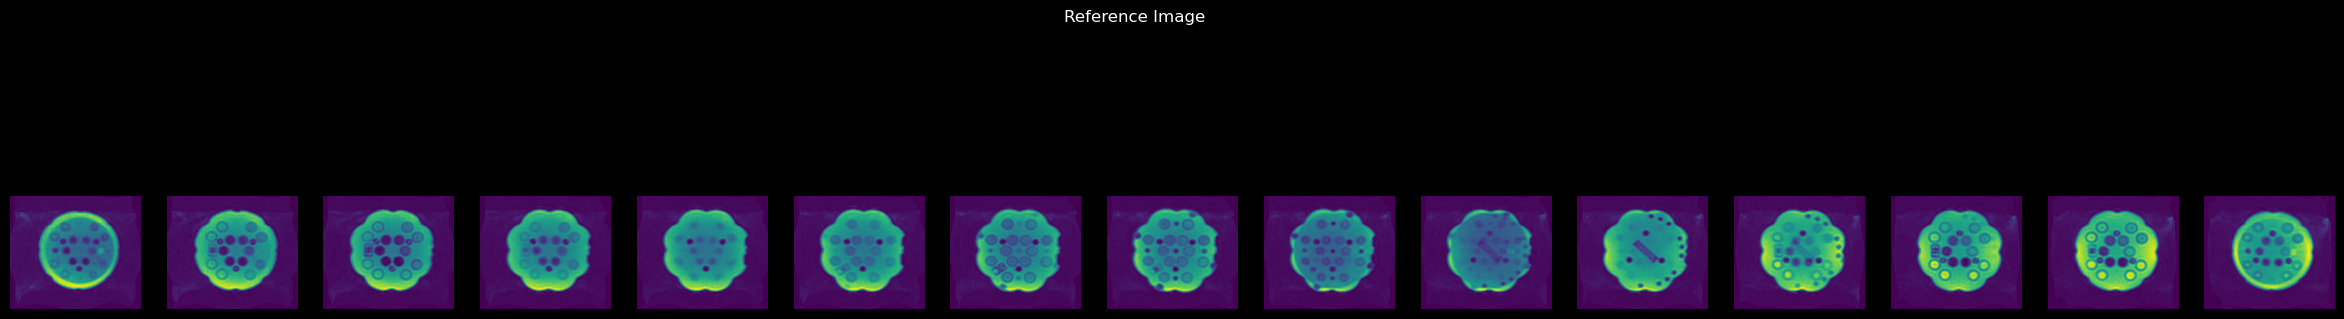

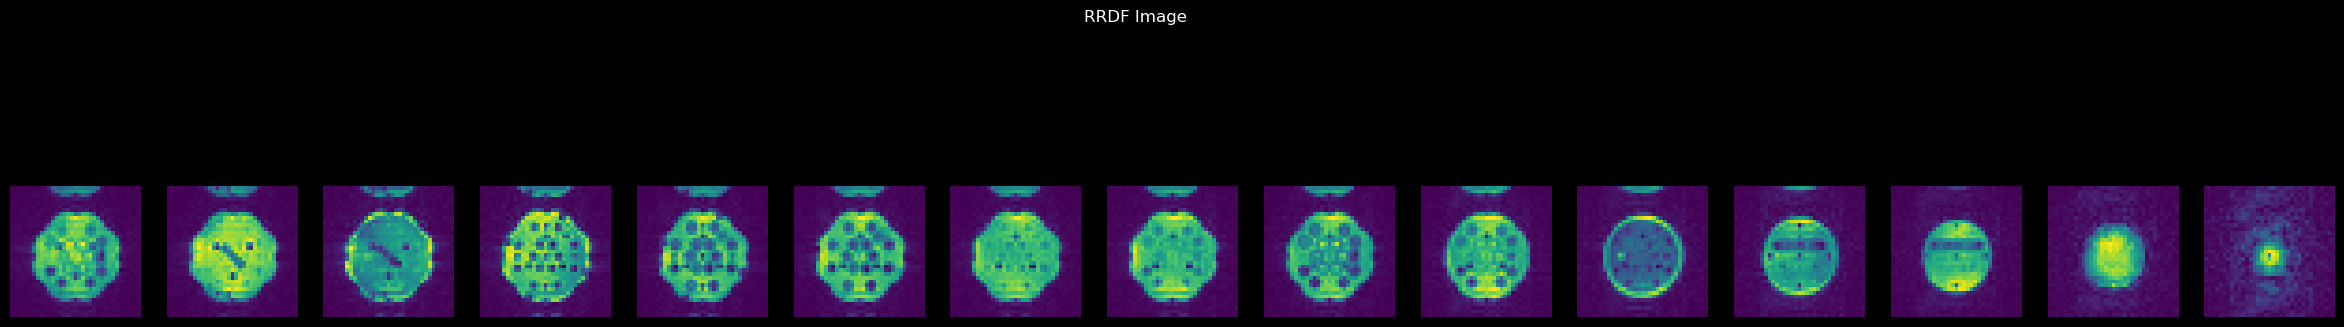

In [8]:
def plot_slices(array, axis, n=10, offset=0, title=None):

    shp = array.shape
    i_slice = shp[axis] // 2 + int(offset)

    fig, axes = plt.subplots(1, n, figsize=(2*n,5))

    for i in range(n):
        
        i_slice = shp[axis] // 2 + int(offset) + i
        
        if axis==0:
            s = [i_slice, slice(0,-1), slice(0,-1)]
        elif axis==1:
            s = [slice(0,-1), i_slice, slice(0,-1)]
        else:
            s = [slice(0,-1), slice(0,-1), i_slice]
        s = tuple(s)

        axes[i].imshow(array[s])
        axes[i].set_axis_off()

    fig.suptitle(title)
    plt.show()


# ------------------------------------------------------------------
# Now we want to make sure our inhomogeneity maps are aligned in orientation with the other figures and maps
# ------------------------------------------------------------------

# Load in a reference dicom of the same phantom
ref_dcm_fname = str(config.CALIBER_DIR / "scan_data/0201/20260428175830488.MRe")
ref_dcm_nii = dcmload.dcm2niix_wrapper(ref_dcm_fname)
ref_dcm_img = ref_dcm_nii.get_fdata()
plot_slices(ref_dcm_img, axis=2, title="Reference Image", offset=-5, n=15)

# Extract an average RRDF image to use for orienting scans
rrdf_img = np.abs(rrdf_df["img1"].mean())
rrdf_spacing = rrdf_df["spacing"].iloc[0]
plot_slices(rrdf_img, axis=2, title="RRDF Image", offset=-5, n=15)

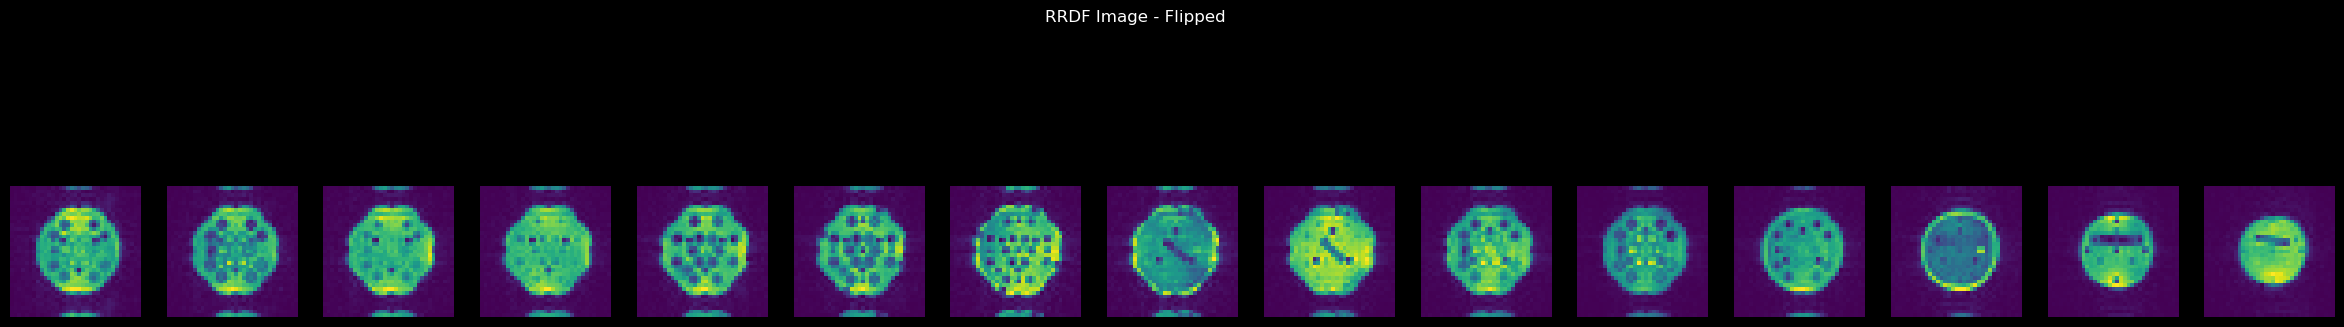

In [9]:
# The axes are actually aligned however need to be flipped
axes_flip = [0, 1, 2]
rrdf_img_flip = np.flip(rrdf_img, axis=axes_flip)
delta_B0_map_flip = np.flip(delta_B0_map, axis=axes_flip)
mask_flip = np.flip(mask, axis=axes_flip)

plot_slices(rrdf_img_flip, axis=2, title="RRDF Image - Flipped", offset=-5, n=15)

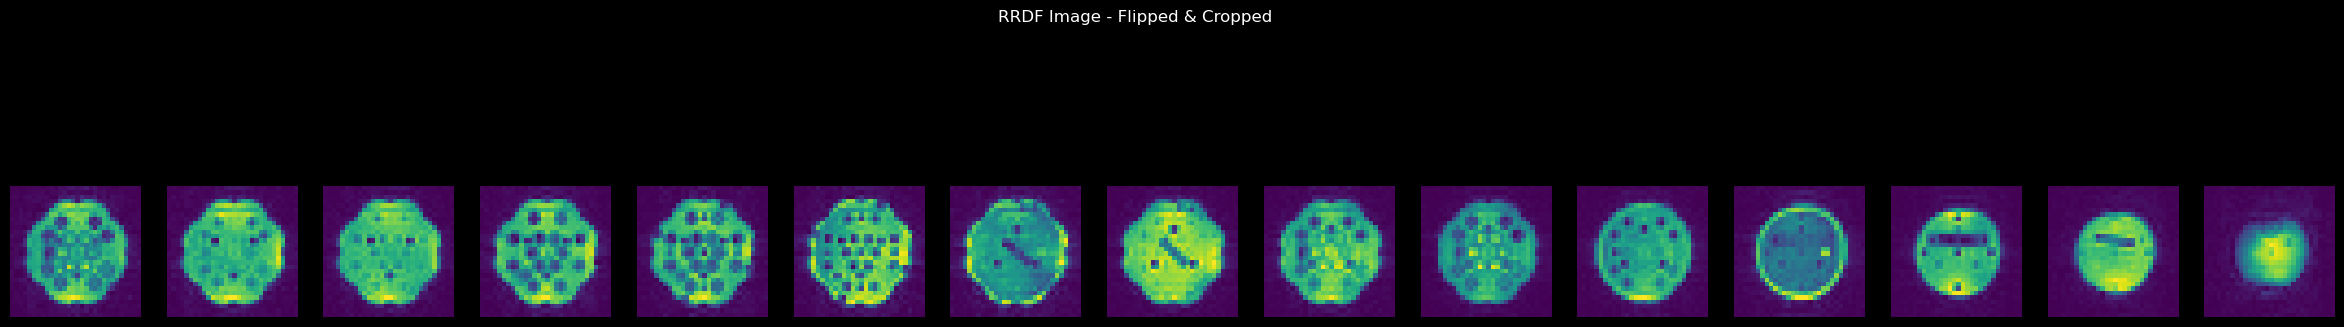

In [10]:
# Crop images to remove aliasing and centre phantom in frame
crop = tuple([slice(2,-3), slice(3, -2), slice(4, -1)])

rrdf_img_crop = rrdf_img_flip[crop]
delta_B0_map_crop = delta_B0_map_flip[crop]
mask_crop = mask_flip[crop]
shp = rrdf_img_crop.shape
sz = shp[0]
i_centre = sz // 2

plot_slices(rrdf_img_crop, axis=2, title="RRDF Image - Flipped & Cropped", offset=-5, n=15)

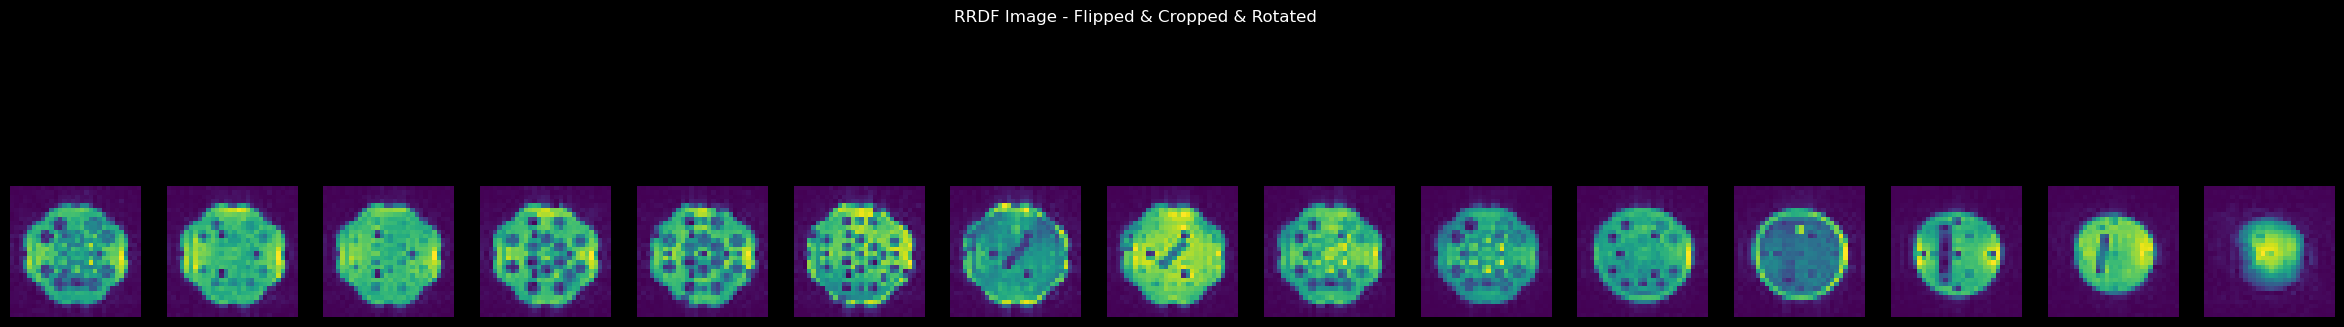

In [11]:
# Now we are aligned with the other data arrays we can apply a 90-deg rotation about the axial-direction
# The reason to do this is to align all axial slices with other plots in the article

rrdf_img_align = np.rot90(rrdf_img_crop, k=1, axes=(0,1))
delta_B0_map_align = np.rot90(delta_B0_map_crop, k=1, axes=(0,1))
mask_align = np.rot90(mask_crop, k=1, axes=(0,1))

# Now the axes are stacked [cor, sag, axi]
plot_slices(rrdf_img_align, axis=2, title="RRDF Image - Flipped & Cropped & Rotated", offset=-5, n=15)

In [12]:
# Save the aligned B0-inhomogeneity map and mask for the spherical-harmonic fitting (b0_sph_harm_fitting.ipynb)
b0_out_fname = deriv_dir / "b0_map_aligned.npz"
np.savez_compressed(b0_out_fname,
                    delta_B0_map=delta_B0_map_align,        # T, referenced to the mean B0, indexed [cor, sag, axi]
                    mask=mask_align,                        # initial signal mask
                    spacing_mm=np.array(rrdf_spacing),      # voxel size (mm)
                    f0_avg=f0_avg)                          # mean centre frequency (Hz)
print(f"Saved aligned B0 map and mask to {b0_out_fname}")

Saved aligned B0 map and mask to b0_mapping/derivatives/b0_map_aligned.npz
